# One program across Core, Data, Train and Tune

A Core task, a Data pipeline, a standalone Train run and a Tune sweep in one graph; the builder emits them in that order as one program.

**When to use it.** End-to-end experiments: prepare inputs, build features, train a baseline and sweep around it in a single notebook.

The picture below is the graph drawn in Eugo's visual Ray builder, and the cell under *Generated code* is the Ray code the builder produced from it. The code is plain Ray: it runs without the builder.

[Back to the gallery](../README.md) · Tested with Ray 2.55.1

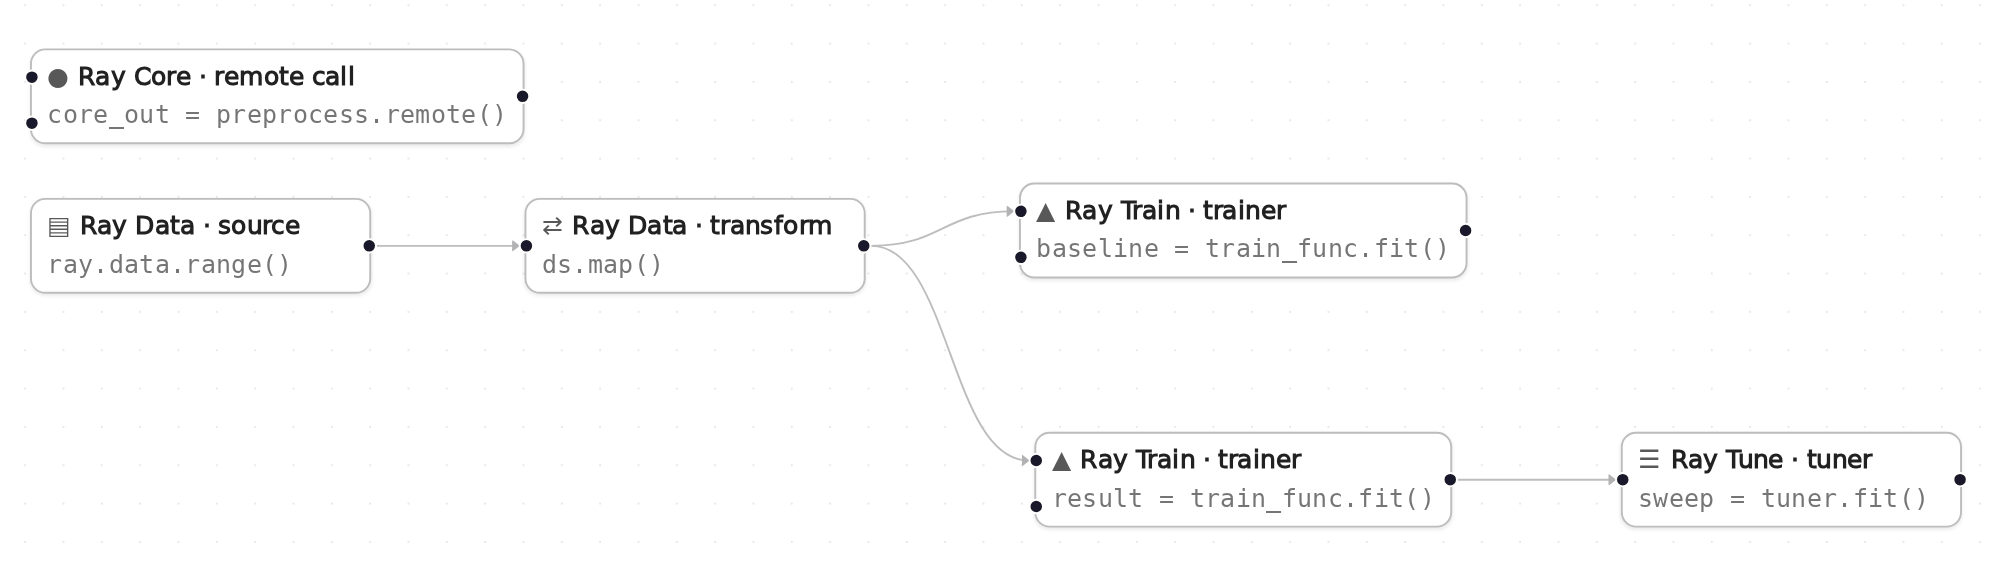

*The graph in Eugo's visual Ray builder.*

## Setup

Start a local Ray instance. The options keep the notebook quiet: no dashboard, and worker logs stay out of the notebook. Ray is capped at four CPUs so the example behaves the same on any machine. The generated code below only calls `ray.init()` when Ray is not running yet, so it reuses this instance.

In [1]:
import ray
ray.init(include_dashboard=False, log_to_driver=False, logging_level="ERROR", num_cpus=4)

RayContext(dashboard_url='', python_version='3.12.3', ray_version='2.55.1', ray_commit='237c2455ebb1ea15a32dd9e1fdeb2d617badc37f')

## User functions

The nodes in the graph call these ordinary Python functions and classes. In the builder you write them in a normal notebook cell, and the generated code refers to them by name.

In [2]:
import ray


def preprocess():
    return "inputs ready"


def add_label(row):
    row["label"] = row["id"] % 2
    return row


def train_func(config=None):
    lr = (config or {}).get("lr", 0.05)
    rows = sum(len(b["id"]) for b in ray.train.get_dataset_shard("train").iter_batches(batch_size=4))
    for i in range(3):
        ray.train.report({"loss": lr / (i + 1), "rows": rows})

## Generated code

This is the cell the visual builder generated from the graph above.

In [3]:
# Generated with Eugo's visual Ray builder

from ray import tune
import ray
from ray.train import RunConfig, ScalingConfig
from ray.train.torch import TorchTrainer
from ray.tune import TuneConfig, Tuner
from ray.tune.integration.ray_train import TuneReportCallback

if not ray.is_initialized():
    ray.init()

_n0 = ray.remote(preprocess).remote()
core_out = ray.get(_n0)

ds_n1 = ray.data.range(16)
ds_n2 = ds_n1.map(add_label)

_trainer_n4 = TorchTrainer(train_func, scaling_config=ScalingConfig(num_workers=1, use_gpu=False), datasets={"train": ds_n2})
baseline = _trainer_n4.fit()

def _tune_driver_n6(config):
    trainer = TorchTrainer(train_func, train_loop_config=config["train_loop_config"], scaling_config=ScalingConfig(num_workers=1, use_gpu=False), datasets={"train": ds_n2}, run_config=RunConfig(callbacks=[TuneReportCallback()]))
    trainer.fit()

_tuner_n6 = Tuner(_tune_driver_n6, param_space={"train_loop_config": {"lr": tune.grid_search([0.01, 0.1])}}, tune_config=TuneConfig(num_samples=1, metric="loss", mode="min", max_concurrent_trials=1))
sweep = _tuner_n6.fit()
best = sweep.get_best_result()

## Check the result

The cell below checks that the generated code did what the graph describes.

In [4]:
assert core_out == "inputs ready", core_out
assert baseline.error is None, baseline.error
assert len(sweep) == 2 and sweep.num_errors == 0, sweep.errors
print("baseline trained without errors")
print("best lr:", best.config["train_loop_config"]["lr"])

baseline trained without errors
best lr: 0.01


## How the graph maps to the code

Each step names a node in the picture, the lines of the generated cell it produced, and what those lines do. The node id (for example `n1`) is also the suffix of the variable that holds the node's result.

**Setup** (lines 1, 3–8 and 10–11)

```python
# Generated with Eugo's visual Ray builder
...
from ray import tune
import ray
from ray.train import RunConfig, ScalingConfig
from ray.train.torch import TorchTrainer
from ray.tune import TuneConfig, Tuner
from ray.tune.integration.ray_train import TuneReportCallback
...
if not ray.is_initialized():
    ray.init()
```

The first line marks the cell as generated. The builder then adds an import for every Ray API the graph uses and a guarded ray.init(), so re-running the cell reuses the running cluster.

**Remote task** (node `n0`, lines 13–14)

```python
_n0 = ray.remote(preprocess).remote()
core_out = ray.get(_n0)
```

A Core task that runs first.

**Source** (node `n1`, line 16)

```python
ds_n1 = ray.data.range(16)
```

The Data source.

**Transform** (node `n2`, line 17)

```python
ds_n2 = ds_n1.map(add_label)
```

map(add_label) adds a label column; its output feeds both trainers.

**Trainer** (node `n4`, lines 19–20)

```python
_trainer_n4 = TorchTrainer(train_func, scaling_config=ScalingConfig(num_workers=1, use_gpu=False), datasets={"train": ds_n2})
baseline = _trainer_n4.fit()
```

A standalone baseline training run.

**Tuner** (node `n6`, lines 22, 24 and 26–28)

```python
def _tune_driver_n6(config):
...
    trainer.fit()
...
_tuner_n6 = Tuner(_tune_driver_n6, param_space={"train_loop_config": {"lr": tune.grid_search([0.01, 0.1])}}, tune_config=TuneConfig(num_samples=1, metric="loss", mode="min", max_concurrent_trials=1))
sweep = _tuner_n6.fit()
best = sweep.get_best_result()
```

A two-point grid search over lr.

**Trainer** (node `n5`, line 23)

```python
    trainer = TorchTrainer(train_func, train_loop_config=config["train_loop_config"], scaling_config=ScalingConfig(num_workers=1, use_gpu=False), datasets={"train": ds_n2}, run_config=RunConfig(callbacks=[TuneReportCallback()]))
```

The trainer the Tuner sweeps; the builder moves it into the per-trial driver function.

## Other ways the builder can emit this graph

The builder can emit the same graph in other forms. They are shown here as text and are not run by this notebook.

### As a standalone script (`core_data_train_tune.py`)

The builder can export the graph as a Python module: the user functions are copied in and the Ray calls go under `if __name__ == "__main__":`. It was run as a script on Ray 2.55.1.

```python
# Generated with Eugo's visual Ray builder

from ray import tune
import ray
from ray.train import RunConfig, ScalingConfig
from ray.train.torch import TorchTrainer
from ray.tune import TuneConfig, Tuner
from ray.tune.integration.ray_train import TuneReportCallback

import ray


def preprocess():
    return "inputs ready"


def add_label(row):
    row["label"] = row["id"] % 2
    return row


def train_func(config=None):
    lr = (config or {}).get("lr", 0.05)
    rows = sum(len(b["id"]) for b in ray.train.get_dataset_shard("train").iter_batches(batch_size=4))
    for i in range(3):
        ray.train.report({"loss": lr / (i + 1), "rows": rows})

if __name__ == "__main__":
    ray.init()

    _n0 = ray.remote(preprocess).remote()
    core_out = ray.get(_n0)

    ds_n1 = ray.data.range(16)
    ds_n2 = ds_n1.map(add_label)

    _trainer_n4 = TorchTrainer(train_func, scaling_config=ScalingConfig(num_workers=1, use_gpu=False), datasets={"train": ds_n2})
    baseline = _trainer_n4.fit()

    def _tune_driver_n6(config):
        trainer = TorchTrainer(train_func, train_loop_config=config["train_loop_config"], scaling_config=ScalingConfig(num_workers=1, use_gpu=False), datasets={"train": ds_n2}, run_config=RunConfig(callbacks=[TuneReportCallback()]))
        trainer.fit()

    _tuner_n6 = Tuner(_tune_driver_n6, param_space={"train_loop_config": {"lr": tune.grid_search([0.01, 0.1])}}, tune_config=TuneConfig(num_samples=1, metric="loss", mode="min", max_concurrent_trials=1))
    sweep = _tuner_n6.fit()
    best = sweep.get_best_result()
    ray.shutdown()
```

## Clean up

Shut down Ray, so the next notebook starts fresh.

In [5]:
ray.shutdown()